# Planta Física: genetic algorithms through four decisions

MA2015.202 · March 2025 · One cumulative notebook.

**Team:** Ángel Nicolás Landa Tapia (A01668133), Luis Fernando Salas López (A01770922), Claudio Ahuatzi Quintana (A01661936).

The notebook is organized as three stacked deliverables.

- **Sections 1–13 (Research)** and the hand-calculation check describe the supplied baseline genetic algorithm with `mutate` as the mutation operator.
- **Sections 14–21 (Development)** replace `mutate` with `mutate_capacity_aware` and compare the two at seed 42.
- **Sections 22–26 (Final)** trace one generation of the identified code, compare two mutation probabilities at the same seed, and interpret the water allocation by building.

Our additions are the written interpretation (Sections 7, 10, 12, 23, 24, 25, 26), an exhaustive optimum check over all 5,103 plans (Section 12), a hand-calculation check against the evaluator (end of the notebook), and a supplementary 100-seed robustness analysis of the operator change (Section 19).

> **Development milestone (B1 and B2): how to read this cumulative notebook**
>
> - **Sections 1–13, Provenance and the hand-calculation check** are our previous work (Research A1/A2 and the supplied baseline GA), kept **unchanged** with their code and outputs. Statements there that no operator was modified describe the baseline.
> - **Sections 14–21** are the Development milestone, where we change one operator.
>
> | Role | What it is | Where |
> |---|---|---|
> | **Baseline** | Supplied GA: binary tournament, one-point crossover, `mutate` (blind ±1 step), one elite | Sections 3–8; rerun in Section 18 |
> | **Variant** | Same GA with `mutate` replaced by `mutate_capacity_aware` | Sections 16–18 |
> | **Modified operator** | **Mutation** only. Selection, crossover, replacement, data and parameters are identical | Section 16 |
>
> The $p=0.50$ run in Sections 9–10 is the kit's parameter variation, not the Development variant.

## 1. We define the problem

We allocate a fraction of treated water to each building to reduce potable-water use. We use aggregate March 2025 demands and retain this building order. The four source records have no imputation, zero or possible-anomaly flags.

| Building | Demand $D_i$ (m³) | Domain of $k_i$ | Maximum reuse |
|---|---:|:---:|---:|
| Aulas 1 | 847.00 | $\{0,\ldots,8\}$ | 80% |
| Biblioteca | 462.00 | $\{0,\ldots,8\}$ | 80% |
| Cedetec | 284.21 | $\{0,\ldots,6\}$ | 60% |
| Aulas 2 | 683.00 | $\{0,\ldots,8\}$ | 80% |
| **Total** | $Q=2276.21$ | | |

We adopt 1,410 m³ as **teaching capacity** from the instructor's calibration; it is not a partner-confirmed capacity. We also treat each building's reuse limit as a teaching assumption.

We encode $k=(k_1,k_2,k_3,k_4)$ using integers: $k_1,k_2,k_4\in\{0,\ldots,8\}$ and $k_3\in\{0,\ldots,6\}$. Each gene $k_i$ is the integer reuse level chosen for building $i$. We turn it into a fraction $x_i=k_i/10$, so one level equals 10% of that building's demand; for example, gene 6 represents 60% reuse. From the fraction we get the two volumes of each building: treated water $T_i=x_iD_i$ and potable water $P_i=D_i-T_i$, so $T_i+P_i=D_i$ always holds. There are $9\times9\times7\times9=5103$ combinations; we explore some using the genetic algorithm.

In [1]:
import numpy as np

BUILDINGS = ("AULAS 1", "BIBLIOTECA", "CEDETEC", "AULAS 2")
DEMAND = np.array([847.0, 462.0, 284.21, 683.0])  # m3, March 2025
LIMITS = np.array([8, 8, 6, 8])  # integer levels; fractions = levels / 10
CAPACITY = 1410.0  # m3; teaching assumption, not confirmed plant capacity

## 2. We calculate water volumes and fitness

We define treated water $T=\sum_iD_i k_i/10$, potable water $P=\sum_iD_i-T$ and excess capacity $E=\max(0,T-C)$. We minimize $P$ subject to the gene domains and $T\le C$.

We rank candidates using $F=P/\sum D_i$ when they are feasible and $F=1+E/C$ when they exceed capacity. Lower fitness is better. A feasible candidate has $F\le1$; an infeasible candidate has $F>1$. We use a numerical tolerance of $10^{-8}$ m³.

We calculated $k=(6,6,6,6)$ by hand, building by building, before running the code:

| Building | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=x_iD_i$ (m³) | $P_i=D_i-T_i$ (m³) | $T_i+P_i$ (m³) |
|---|---:|:---:|:---:|---:|---:|---:|
| Aulas 1 | 847.00 | 6 | 0.6 | 508.200 | 338.800 | 847.000 |
| Biblioteca | 462.00 | 6 | 0.6 | 277.200 | 184.800 | 462.000 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 | 284.210 |
| Aulas 2 | 683.00 | 6 | 0.6 | 409.800 | 273.200 | 683.000 |
| **Total** | 2276.21 | | | **1365.726** | **910.484** | 2276.210 |

Substitutions: $847\times0.6=508.200$, $462\times0.6=277.200$, $284.21\times0.6=170.526$ and $683\times0.6=409.800$ m³. Adding them, $T=508.200+277.200+170.526+409.800=1365.726$ m³ and $P=338.800+184.800+113.684+273.200=910.484$ m³.

Conservation checks: each row satisfies $T_i+P_i=D_i$, and in total $T+P=1365.726+910.484=2276.210=Q$ m³.

Capacity is satisfied because $T=1365.726\le1410$ m³, which leaves a margin of 44.274 m³, so $E=0$ m³ and $F=910.484/2276.21=0.4$ (no units).

In [2]:
def evaluate(genes: np.ndarray) -> dict:
    """Return physical totals and fitness (lower is better) for four integer genes."""
    genes = np.asarray(genes)
    if genes.shape != (4,) or not np.issubdtype(genes.dtype, np.integer):
        raise ValueError("Expected four integer genes in building order.")
    if np.any(genes < 0) or np.any(genes > LIMITS):
        raise ValueError("Genes outside the allowed building domains.")
    treated = float(np.sum(DEMAND * genes / 10))
    potable = float(np.sum(DEMAND) - treated)
    excess = max(0.0, treated - CAPACITY)
    feasible = excess <= 1e-8  # numerical tolerance in m3
    fitness = potable / float(np.sum(DEMAND)) if feasible else 1 + excess / CAPACITY
    return dict(treated=treated, potable=potable, excess=excess,
                feasible=feasible, fitness=fitness)

We check three candidates: zero reuse, uniform 60% reuse and the maximum level in each domain. All three have valid genes, but only the first two satisfy capacity. The keys `treated`, `potable`, `excess`, `feasible` and `fitness` correspond to $T$, $P$, $E$, feasibility and $F$.

In [3]:
cases = [np.zeros(4, dtype=int), np.array([6, 6, 6, 6]), LIMITS.copy()]
for genes in cases:
    print(genes, evaluate(genes))
assert np.isclose(evaluate(cases[1])["potable"], 910.484)
assert evaluate(cases[1])["feasible"]
assert not evaluate(cases[2])["feasible"]

[0 0 0 0] {'treated': 0.0, 'potable': 2276.21, 'excess': 0.0, 'feasible': True, 'fitness': 1.0}
[6 6 6 6] {'treated': 1365.7259999999999, 'potable': 910.4840000000002, 'excess': 0.0, 'feasible': True, 'fitness': 0.4000000000000001}
[8 8 6 8] {'treated': 1764.1260000000002, 'potable': 512.0839999999998, 'excess': 354.1260000000002, 'feasible': False, 'fitness': 1.2511531914893619}


We also calculated the maximum plan $k=(8,8,6,8)$ by hand:

| Building | $D_i$ (m³) | $k_i$ | $x_i$ | $T_i=x_iD_i$ (m³) | $P_i=D_i-T_i$ (m³) | $T_i+P_i$ (m³) |
|---|---:|:---:|:---:|---:|---:|---:|
| Aulas 1 | 847.00 | 8 | 0.8 | 677.600 | 169.400 | 847.000 |
| Biblioteca | 462.00 | 8 | 0.8 | 369.600 | 92.400 | 462.000 |
| Cedetec | 284.21 | 6 | 0.6 | 170.526 | 113.684 | 284.210 |
| Aulas 2 | 683.00 | 8 | 0.8 | 546.400 | 136.600 | 683.000 |
| **Total** | 2276.21 | | | **1764.126** | **512.084** | 2276.210 |

Substitutions: $847\times0.8=677.600$, $462\times0.8=369.600$, $284.21\times0.6=170.526$ and $683\times0.8=546.400$ m³. Conservation holds per building and in total: $T+P=1764.126+512.084=2276.210=Q$ m³.

The maximum plan uses 1764.126 m³ of treated water, exceeds capacity by $E=1764.126-1410=354.126$ m³ and obtains $F=1+354.126/1410=1.2512>1$. Although it uses less potable water, we reject it as infeasible. Our hand calculations for both candidates match the evaluator (see the check at the end of the notebook).

## 3. We generate a population

A population is a list of candidates. We sample each gene within its domain, including both endpoints. Sampling does not guarantee compliance with capacity: fitness also ranks infeasible candidates. We fix the seed to reproduce this demonstration.

In [4]:
def random_individual(rng: np.random.Generator) -> np.ndarray:
    """Sample one valid discrete chromosome; capacity is checked by evaluate."""
    return rng.integers(0, LIMITS + 1)

rng_demo = np.random.default_rng(42)
population_demo = [random_individual(rng_demo) for _ in range(4)]
for genes in population_demo:
    print(genes, evaluate(genes)["fitness"])

[0 6 4 3] 0.7382561362967388
[3 7 0 6] 0.5662526744017468
[1 0 3 8] 0.6852825530157587
[6 6 5 7] 0.38248008751389373


## 4. We select parents through tournaments

We sample two distinct candidates and choose the one with lower $F$. We repeat the process to select another parent; the same individual can win several tournaments. Selection favors lower fitness without always sorting the entire population. We return a copy to protect the original.

In [5]:
def tournament(population: list, rng: np.random.Generator) -> np.ndarray:
    """Return an independent copy of the better of two sampled individuals."""
    indices = rng.choice(len(population), size=2, replace=False)
    winner = min((population[i] for i in indices), key=lambda x: evaluate(x)["fitness"])
    return winner.copy()

parent_a = tournament(population_demo, rng_demo)
parent_b = tournament(population_demo, rng_demo)
print(parent_a, parent_b)

[3 7 0 6] [3 7 0 6]


## 5. We combine information through one-point crossover

We choose a cut between gene positions and combine the beginning of the first parent with the end of the second. We preserve each building's position. For parents $(6,6,6,6)$ and $(8,2,4,3)$ with cut 2, we obtain $(6,6,4,3)$. Crossover preserves gene domains but can produce excess capacity.

In [6]:
def crossover(parent_a: np.ndarray, parent_b: np.ndarray,
              rng: np.random.Generator) -> np.ndarray:
    """Create one child using a cut between genes and preserving their positions."""
    cut = int(rng.integers(1, len(LIMITS)))
    return np.concatenate((parent_a[:cut], parent_b[cut:]))

child_demo = crossover(parent_a, parent_b, rng_demo)
print(child_demo, evaluate(child_demo))

[3 7 0 6] {'treated': 987.3, 'potable': 1288.91, 'excess': 0.0, 'feasible': True, 'fitness': 0.5662526744017468}


## 6. We introduce variation through mutation

We apply the probability to each gene, rather than to the whole chromosome. Each selected gene increases or decreases by one valid level. At zero we can only increase; at the maximum we can only decrease. With $p=0.25$ and four genes, we expect one selected gene per child on average, rather than exactly one. Mutation can improve or worsen fitness.

In [7]:
def mutate(child: np.ndarray, probability: float,
           rng: np.random.Generator) -> np.ndarray:
    """Independently move each selected gene one valid discrete step."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            result[i] = rng.choice(neighbors)
    return result

mutated_demo = mutate(child_demo, 0.25, rng_demo)
print(child_demo, mutated_demo, evaluate(mutated_demo))

[3 7 0 6] [3 7 0 7] {'treated': 1055.6, 'potable': 1220.6100000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.5362466556249205}


## 7. We replace the population and preserve one elite

We copy the best individual without changing it and fill the remaining positions with children. We keep the population size constant. Elitism prevents loss of the best fitness value; it does not establish that we have found the optimum. With an independent copy, mutating a child does not change its parent or the elite.

In [8]:
def next_generation(population: list, probability: float,
                    rng: np.random.Generator) -> list:
    """Preserve one independent elite and replace all other individuals."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        replacement.append(mutate(child, probability, rng))
    return replacement

replacement_demo = next_generation(population_demo, 0.25, rng_demo)
print(min(evaluate(x)["fitness"] for x in population_demo))
print(min(evaluate(x)["fitness"] for x in replacement_demo))

0.38248008751389373
0.38248008751389373


**One generation, step by step.** In the demo population of four, the best candidate is (6,6,5,7) with $F=0.3825$. Both tournaments returned (3,7,0,6) ($F=0.5663$), so the same individual became both parents. Crossover of two identical parents returns the same genes, so the child is (3,7,0,6). Mutation moved Aulas 2 from 6 to 7, which raised $T$ to 1055.6 m³ and lowered $F$ to 0.5362. In the full replacement, the elite (6,6,5,7) was copied unchanged, so the best $F$ stayed at 0.3825 because no child beat it.

## 8. We complete the cycle

We initialize, evaluate and repeat selection, crossover, mutation and replacement for a fixed number of generations. We record the initial best $F$ and the best value after each generation. With 20 generations, we obtain 21 values, including initialization. We do not expect improvement at every step.

In [9]:
def run_ga(population_size: int = 20, generations: int = 20,
           mutation_probability: float = 0.25, seed: int = 42) -> dict:
    """Run a small canonical GA and retain the best fitness at each generation."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation(population, mutation_probability, rng)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history))

## 9. We run the baseline and a mutation variation

We use 20 individuals, 20 generations and seed 42. In the variation, we change only the per-gene mutation probability from 0.25 to 0.50 and keep the data, gene domains, capacity and all other parameters fixed. Both runs use the supplied baseline operators without modification. This comparison describes two runs; it does not show that either configuration is better in general.

In [10]:
CONFIG = dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
baseline = run_ga(**CONFIG)
variant_config = {**CONFIG, "mutation_probability": 0.50}
variant = run_ga(**variant_config)
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    print(label, "genes =", result["genes"], "fractions =", result["genes"] / 10)
    print(result["metrics"])

p=0.25 genes = [7 4 3 8] fractions = [0.7 0.4 0.3 0.8]
{'treated': 1409.363, 'potable': 866.847, 'excess': 0.0, 'feasible': True, 'fitness': 0.38082909749100474}
p=0.50 genes = [5 7 4 8] fractions = [0.5 0.7 0.4 0.8]
{'treated': 1406.984, 'potable': 869.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.3818742558902738}


## 10. We visualize and interpret

We read the horizontal axis as generation and the vertical axis as best fitness. A decrease represents improvement; a plateau means we retain the best value. We always connect the plot to feasibility and water volumes. A descending curve alone does not establish physical validity.

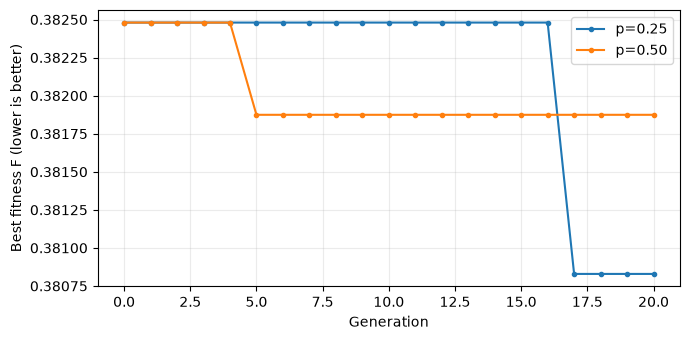

In [11]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.set(xlabel='Generation', ylabel='Best fitness F (lower is better)')
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation.** The only changed parameter is the per-gene mutation probability (0.25 vs 0.50). Both runs use the same seed, so they start from the same population, with best $F=0.3825$.

| Run | Final genes | $T$ (m³) | $P$ (m³) | Feasible | Best $F$ | Improvement at generation |
|---|---|---:|---:|:---:|---:|---:|
| $p=0.25$ | (7,4,3,8) | 1409.363 | 866.847 | Yes | 0.3808 | 17 |
| $p=0.50$ | (5,7,4,8) | 1406.984 | 869.226 | Yes | 0.3819 | 5 |

The variant improved earlier, but the baseline reached a lower final value and uses 2.379 m³ less potable water. Long plateaus show that elitism keeps the best value while no child beats it. Both final plans are feasible. These are two single runs with one seed, so they do not show that either probability is better in general.

## 11. We check reproduction

We repeat the baseline with the same seed and check that genes and history match. We also check that the best fitness never gets worse, as elitism requires. We restarted the kernel and ran the notebook from top to bottom to rule out dependence on previous runs. This repetition is a technical check, not a third configuration.

In [12]:
repeated = run_ga(**CONFIG)
np.testing.assert_array_equal(baseline["genes"], repeated["genes"])
np.testing.assert_array_equal(baseline["history"], repeated["history"])
assert np.all(np.diff(baseline["history"]) <= 1e-12)
print('Reproduction and elitism checked.')

Reproduction and elitism checked.


## 12. We interpret the physical result and limitations

We evaluate all 5,103 combinations to compare the GA results with the true optimum of this model.

In [13]:
import itertools

all_plans = [np.array(k) for k in itertools.product(*(range(limit + 1) for limit in LIMITS))]
optimum = min(all_plans, key=lambda x: evaluate(x)["fitness"])
print(len(all_plans), "plans checked; optimum =", optimum, evaluate(optimum))
for label, result in [("p=0.25", baseline), ("p=0.50", variant)]:
    gap = result["metrics"]["potable"] - evaluate(optimum)["potable"]
    print(f"{label}: {gap:.3f} m3 more potable water than the optimum")

5103 plans checked; optimum = [8 6 4 5] {'treated': 1409.984, 'potable': 866.2260000000001, 'excess': 0.0, 'feasible': True, 'fitness': 0.38055627556332683}
p=0.25: 0.621 m3 more potable water than the optimum
p=0.50: 3.000 m3 more potable water than the optimum


#### Physical interpretation. 
Both final plans are feasible and use almost all of the 1,410 m³ capacity (margins of 0.637 and 3.016 m³). They reduce potable water from 2276.21 m³ with no reuse to about 867–869 m³, a reduction of about 62%. The optimum of this model is (8,6,4,5), with $T=1409.984$ m³ and $P=866.226$ m³. The baseline result is 0.621 m³ above it and the variant 3.000 m³ above it. Many different allocations fill the capacity almost equally well, so runs can end with different building splits but nearly the same potable-water use.

**Limitations.**
- We use one month (March 2025) of aggregate demand; other months may differ.
- The 1,410 m³ capacity and the per-building limits are teaching assumptions, not confirmed plant data.
- The model ignores water quality, storage, pipes, daily timing and cost.
- Genes move in 10% steps, so finer allocations are not considered.
- Each configuration ran once with one seed and a small population.

Results describe this teaching model; they are not a validated hydraulic or sanitary recommendation.

## 13. Evidence in this notebook

- **Research:** A1 formulation and assumptions (Sections 1–2); A2 hand calculation and comparison with the evaluator (Section 2 and the final check cell).
- **Development:** functional GA cycle (Sections 3–8, 11) and a substantive modification of the mutation operator with a controlled baseline/variant comparison (Sections 14–21). Baseline: `mutate` (blind ±1). Variant: `mutate_capacity_aware` (capacity-aware ±1). Both operators are available as `run_ga_with(..., mutation_operator=...)`, which is what the Final sections rebuild on.
- **Final:** Sections 22–26: C1 traced generation (Section 23), C2 comparison of $p_m=0.25$ and $0.50$ with its plot (Section 24) and C3 interpretation by building, capacity and assumptions (Section 25). Sections 3–12 hold the earlier walk-through of the supplied baseline that the Final sections build on.

## Provenance and environment

We use the four March 2025 records from the supplied water-consumption data and the instructor-calibrated teaching limits. Notebook metadata retains the records and source hashes. The monthly case and code are self-contained.

With Python 3.12-3.14 and the supplied environment files, prepare the environment with `uv sync --locked` and open Jupyter with `uv run jupyter lab`. NumPy performs the calculations and Matplotlib draws the plot. Results describe this teaching model; they do not establish a validated hydraulic or sanitary recommendation.

### Check of our hand calculations (Research A2)

We compare our hand results for (6,6,6,6) and (8,8,6,8) with the evaluator.

In [14]:
import numpy as np

# Manual candidates
manual = np.array([6, 6, 6, 6])
maximum = LIMITS.copy()  # [8, 8, 6, 8]

print("Manual calculation check")
print("-" * 60)
for label, genes in [("(6,6,6,6)", manual), ("(8,8,6,8)", maximum)]:
    m = evaluate(genes)
    print(f"{label}: genes={genes}, T={m['treated']:.6f} m3, "
          f"P={m['potable']:.6f} m3, E={m['excess']:.6f} m3, "
          f"feasible={m['feasible']}, F={m['fitness']:.12f}")

# Assertions for (6,6,6,6)
m1 = evaluate(manual)
assert np.isclose(m1['treated'], 1365.726, atol=1e-8)
assert np.isclose(m1['potable'], 910.484, atol=1e-8)
assert np.isclose(m1['excess'], 0.0, atol=1e-8)
assert m1['feasible']
assert np.isclose(m1['fitness'], 0.4, atol=1e-12)

# Assertions for (8,8,6,8)
m2 = evaluate(maximum)
assert np.isclose(m2['treated'], 1764.126, atol=1e-8)
assert np.isclose(m2['potable'], 512.084, atol=1e-8)
assert np.isclose(m2['excess'], 354.126, atol=1e-8)
assert not m2['feasible']
assert np.isclose(m2['fitness'], 1 + 354.126/1410, atol=1e-12)

Manual calculation check
------------------------------------------------------------
(6,6,6,6): genes=[6 6 6 6], T=1365.726000 m3, P=910.484000 m3, E=0.000000 m3, feasible=True, F=0.400000000000
(8,8,6,8): genes=[8 8 6 8], T=1764.126000 m3, P=512.084000 m3, E=354.126000 m3, feasible=False, F=1.251153191489


**Comparison of manual and evaluator values.** Manual values are our hand results from Section 2; evaluator values come from `evaluate` in the cell above. Difference = evaluator − manual. We display volumes rounded to 3 decimals (m³) and $F$ rounded to 7 decimals; the asserts compare unrounded values with tolerances of $10^{-8}$ m³ for volumes and $10^{-12}$ for $F$.

| Candidate | Metric | Manual value | Evaluator value | Difference |
|---|---|---:|---:|---:|
| (6,6,6,6) | $T$ (m³) | 1365.726 | 1365.726 | $-2.3\times10^{-13}$ |
| (6,6,6,6) | $P$ (m³) | 910.484 | 910.484 | $1.1\times10^{-13}$ |
| (6,6,6,6) | $E$ (m³) | 0.000 | 0.000 | 0 |
| (6,6,6,6) | $F$ | 0.4000000 | 0.4000000 | $5.6\times10^{-17}$ |
| (6,6,6,6) | Feasible | Yes | Yes | — |
| (8,8,6,8) | $T$ (m³) | 1764.126 | 1764.126 | $2.3\times10^{-13}$ |
| (8,8,6,8) | $P$ (m³) | 512.084 | 512.084 | $-1.1\times10^{-13}$ |
| (8,8,6,8) | $E$ (m³) | 354.126 | 354.126 | $2.3\times10^{-13}$ |
| (8,8,6,8) | $F$ | 1.2511532 | 1.2511532 | $2.2\times10^{-16}$ |
| (8,8,6,8) | Feasible | No | No | — |

All differences come from floating-point rounding and are far below our tolerances, so all manual calculations match the evaluator.

## 14. Development milestone: baseline, variant and modified operator

We now build and test a variant of the GA by changing **one operator: mutation**. The baseline stays intact: the functions `evaluate`, `random_individual`, `tournament`, `crossover`, `mutate`, `next_generation` and `run_ga` defined above are not modified or redefined. The variant adds a new mutation function and a GA loop that receives the mutation operator as an argument.

**Controlled conditions.** Both runs use exactly the same configuration; the only difference is the mutation operator:

| Condition | Baseline | Variant |
|---|---|---|
| Data, gene domains, capacity, fitness | Sections 1–2 | Same |
| Initialization | `random_individual` | Same |
| Selection | `tournament` (binary) | Same |
| Crossover | `crossover` (one-point) | Same |
| **Mutation** | **`mutate`** (blind ±1 step) | **`mutate_capacity_aware`** |
| Replacement | Generational, 1 elite | Same |
| Population / generations | 20 / 20 | 20 / 20 |
| Mutation probability $p$ | 0.25 | 0.25 |
| Seed | 42 | 42 |

## 15. B1 — Limitation of the baseline mutation

The baseline mutation does not use the capacity constraint. When a gene is selected, it moves up or down with equal probability (only one direction at a domain edge), whatever the current $T$ is. Good plans sit just below $C=1410$ m³. One level of each building is worth a fixed amount of treated water, so the size of a single step depends on the building:

| Building | One level $=D_i/10$ (m³) |
|---|---:|
| Aulas 1 | 84.700 |
| Biblioteca | 46.200 |
| Cedetec | 28.421 |
| Aulas 2 | 68.300 |

Once a plan's slack $C-T$ is below 28.421 m³, **every** upward step makes it infeasible. Its fitness then jumps above 1 and it cannot win a tournament against any feasible plan. For good parents, about half of the mutated genes are therefore wasted offspring. A downward step stays feasible but adds 28–85 m³ of potable water. An improvement near the boundary needs a *coordinated* move: lower one building and raise another with a smaller step. Blind mutation produces such pairs rarely, and when the order is wrong it produces an infeasible plan.

The cell below shows this with the baseline's own best plan at seed 42, (7,4,3,8): it has only 0.637 m³ of slack, and each possible upward step breaks capacity.

In [15]:
near_boundary = np.array([7, 4, 3, 8])
m = evaluate(near_boundary)
print(f"Plan {near_boundary}: T = {m['treated']:.3f} m3, slack = {CAPACITY - m['treated']:.3f} m3")
for i, name in enumerate(BUILDINGS):
    for step in (-1, +1):
        trial = near_boundary.copy()
        trial[i] += step
        if not 0 <= trial[i] <= LIMITS[i]:
            continue
        t = evaluate(trial)
        print(f"  {name:<10} {step:+d}: T = {t['treated']:8.3f}  E = {t['excess']:6.3f}  "
              f"feasible = {t['feasible']!s:<5}  F = {t['fitness']:.4f}")

Plan [7 4 3 8]: T = 1409.363 m3, slack = 0.637 m3
  AULAS 1    -1: T = 1324.663  E =  0.000  feasible = True   F = 0.4180
  AULAS 1    +1: T = 1494.063  E = 84.063  feasible = False  F = 1.0596
  BIBLIOTECA -1: T = 1363.163  E =  0.000  feasible = True   F = 0.4011
  BIBLIOTECA +1: T = 1455.563  E = 45.563  feasible = False  F = 1.0323
  CEDETEC    -1: T = 1380.942  E =  0.000  feasible = True   F = 0.3933
  CEDETEC    +1: T = 1437.784  E = 27.784  feasible = False  F = 1.0197
  AULAS 2    -1: T = 1341.063  E =  0.000  feasible = True   F = 0.4108


## 16. B1 — Hypothesis and the modified operator

**Hypothesis.** If mutation uses the capacity information the evaluator already provides, so that it never chooses a step that pushes a plan over capacity, then (a) far fewer offspring will be infeasible, and (b) the GA will spend its limited budget (20 × 20 evaluations) on feasible plans near the boundary. We therefore expect the final plan to use less potable water, or at least no more, than the baseline under the same seed.

**Change (capacity-aware mutation).** We keep the same per-gene probability $p$, the same ±1 step and the same gene order. When a gene is selected:

1. We compute the child's current $T$, including steps already applied to earlier genes in the same child.
2. A downward step is always allowed. An upward step is allowed only if it keeps $T\le C$.
3. The new value is drawn uniformly from the allowed steps. If no step is allowed (a gene at 0 whose only step is upward and does not fit), the gene stays unchanged. This is the only case in which a selected gene does not move. It is rare, and it is required for the guarantee below.

Consequences: a feasible child cannot become infeasible through mutation; an infeasible child (produced by crossover) can only be pushed back toward capacity; and because $T$ is updated gene by gene, a downward step on one building can make room for an upward step on a later one in the same child. This creates the coordinated moves described above. The operator is still stochastic and does not search for the best step, because we do not want to turn mutation into a greedy local search.

In [16]:
def mutate_capacity_aware(child: np.ndarray, probability: float,
                          rng: np.random.Generator) -> np.ndarray:
    """Move each selected gene one step, never choosing an upward step that breaks capacity."""
    if not 0 <= probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    result = child.copy()
    for i, limit in enumerate(LIMITS):
        if rng.random() < probability:
            treated = float(np.sum(DEMAND * result / 10))
            neighbors = [v for v in (result[i] - 1, result[i] + 1) if 0 <= v <= limit]
            allowed = [v for v in neighbors
                       if v < result[i] or treated + DEMAND[i] / 10 <= CAPACITY + 1e-8]
            if allowed:
                result[i] = rng.choice(allowed)
    return result

We check the operator's guarantees on 5,000 random children before using it in the GA: domains are respected, a feasible child stays feasible, and an infeasible child's treated water never increases. (A first draft fell back to the blind step when no step was allowed. This check showed that the draft could still push a gene at 0 over capacity, so we corrected it before any of the runs reported below.)

In [17]:
rng_check = np.random.default_rng(0)
for _ in range(5000):
    child = random_individual(rng_check)
    before = evaluate(child)
    after = evaluate(mutate_capacity_aware(child, 0.5, rng_check))  # also validates domains
    if before["feasible"]:
        assert after["feasible"]
    else:
        assert after["treated"] <= before["treated"] + 1e-9
print("Capacity-aware mutation: domains, feasibility preservation and repair direction checked.")

rng_variant_demo = np.random.default_rng(7)
print("From the near-boundary plan (7,4,3,8) with p = 1:")
for _ in range(4):
    trial = mutate_capacity_aware(near_boundary, 1.0, rng_variant_demo)
    t = evaluate(trial)
    print(f"   {trial}  T = {t['treated']:8.3f}  feasible = {t['feasible']}")

Capacity-aware mutation: domains, feasibility preservation and repair direction checked.
From the near-boundary plan (7,4,3,8) with p = 1:
   [6 5 4 7]  T = 1330.984  feasible = True
   [6 3 4 7]  T = 1238.584  feasible = True
   [6 5 2 7]  T = 1274.142  feasible = True
   [6 5 4 7]  T = 1330.984  feasible = True


## 17. B1 — Functional GA cycle with a pluggable mutation operator

`run_ga_with` repeats the loop of `run_ga` (Section 8) step by step, with one difference: the mutation operator is passed as an argument. It also counts how many generated children are infeasible after mutation. That counter is a diagnostic only: it reads `evaluate` and draws no random numbers, so it does not change the run.

To show that the baseline is preserved, we run `run_ga_with(mutation_operator=mutate)` and check that it matches the Section 9 baseline (`baseline`) exactly: same final genes and the same best fitness at every generation.

In [18]:
import math


def next_generation_with(population: list, probability: float, rng: np.random.Generator,
                         mutation_operator, stats: dict) -> list:
    """Section 7 replacement with a pluggable mutation operator and an infeasibility counter."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    while len(replacement) < len(population):
        parent_a = tournament(population, rng)
        parent_b = tournament(population, rng)
        child = crossover(parent_a, parent_b, rng)
        child = mutation_operator(child, probability, rng)
        stats["children"] += 1
        stats["infeasible"] += not evaluate(child)["feasible"]
        replacement.append(child)
    return replacement


def run_ga_with(population_size: int = 20, generations: int = 20,
                mutation_probability: float = 0.25, seed: int = 42,
                mutation_operator=mutate) -> dict:
    """Section 8 GA cycle with the chosen mutation operator."""
    if not isinstance(population_size, int) or population_size < 2:
        raise ValueError("Population size must be an integer of at least two.")
    if not isinstance(generations, int) or generations < 1:
        raise ValueError("Generations must be a positive integer.")
    if not 0 <= mutation_probability <= 1:
        raise ValueError("Mutation probability must be between zero and one.")
    rng = np.random.default_rng(seed)
    stats = dict(children=0, infeasible=0)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    for _ in range(generations):
        population = next_generation_with(population, mutation_probability, rng,
                                          mutation_operator, stats)
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return dict(genes=best, metrics=evaluate(best), history=np.array(history),
                infeasible_share=stats["infeasible"] / stats["children"],
                unique_final=len({tuple(x) for x in population}))


assert CONFIG == dict(population_size=20, generations=20, mutation_probability=0.25, seed=42)
dev_baseline = run_ga_with(**CONFIG, mutation_operator=mutate)

np.testing.assert_array_equal(dev_baseline["genes"], baseline["genes"])        # Section 9 result
np.testing.assert_array_equal(dev_baseline["history"], baseline["history"])
np.testing.assert_array_equal(dev_baseline["genes"], [7, 4, 3, 8])
print("Baseline preserved: run_ga_with(mutate) reproduces the Section 9 baseline exactly.")

Baseline preserved: run_ga_with(mutate) reproduces the Section 9 baseline exactly.


## 18. B2 — Controlled comparison at seed 42

Both runs use `CONFIG` (20 individuals, 20 generations, $p=0.25$, seed 42), so they start from the **same initial population**. The only difference is the mutation operator. We report each plan's distance to the exhaustive optimum from Section 12.

In [19]:
dev_variant = run_ga_with(**CONFIG, mutation_operator=mutate_capacity_aware)
dev_runs = [("Baseline (mutate)", dev_baseline), ("Variant (mutate_capacity_aware)", dev_variant)]
opt = evaluate(optimum)
print("Configuration for both runs:", CONFIG)
print(f"Exhaustive optimum (Section 12): {optimum}, T = {opt['treated']:.3f} m3, "
      f"P = {opt['potable']:.3f} m3\n")

for label, result in dev_runs:
    g, mt = result["genes"], result["metrics"]
    print(label)
    print(f"  chromosome k = {tuple(int(v) for v in g)}, fractions x = {tuple(float(v) for v in g / 10)}")
    print(f"  {'Building':<11}{'D (m3)':>9}{'T_i (m3)':>11}{'P_i (m3)':>11}")
    for name, d, k in zip(BUILDINGS, DEMAND, g):
        print(f"  {name:<11}{d:>9.2f}{d * k / 10:>11.3f}{d - d * k / 10:>11.3f}")
    print(f"  {'Total':<11}{DEMAND.sum():>9.2f}{mt['treated']:>11.3f}{mt['potable']:>11.3f}")
    print(f"  E = {mt['excess']:.3f} m3, slack = {CAPACITY - mt['treated']:.3f} m3, "
          f"feasible = {mt['feasible']}, F = {mt['fitness']:.6f}")
    print(f"  gap to optimum = {mt['potable'] - opt['potable']:.3f} m3 potable, "
          f"first improvement at generation {int(np.argmax(result['history'] < result['history'][0]))}, "
          f"infeasible children = {result['infeasible_share']:.1%}, "
          f"distinct plans in final population = {result['unique_final']}\n")

Configuration for both runs: {'population_size': 20, 'generations': 20, 'mutation_probability': 0.25, 'seed': 42}
Exhaustive optimum (Section 12): [8 6 4 5], T = 1409.984 m3, P = 866.226 m3

Baseline (mutate)
  chromosome k = (7, 4, 3, 8), fractions x = (0.7, 0.4, 0.3, 0.8)
  Building      D (m3)   T_i (m3)   P_i (m3)
  AULAS 1       847.00    592.900    254.100
  BIBLIOTECA    462.00    184.800    277.200
  CEDETEC       284.21     85.263    198.947
  AULAS 2       683.00    546.400    136.600
  Total        2276.21   1409.363    866.847
  E = 0.000 m3, slack = 0.637 m3, feasible = True, F = 0.380829
  gap to optimum = 0.621 m3 potable, first improvement at generation 17, infeasible children = 21.8%, distinct plans in final population = 19

Variant (mutate_capacity_aware)
  chromosome k = (5, 7, 4, 8), fractions x = (0.5, 0.7, 0.4, 0.8)
  Building      D (m3)   T_i (m3)   P_i (m3)
  AULAS 1       847.00    423.500    423.500
  BIBLIOTECA    462.00    323.400    138.600
  CEDETEC      

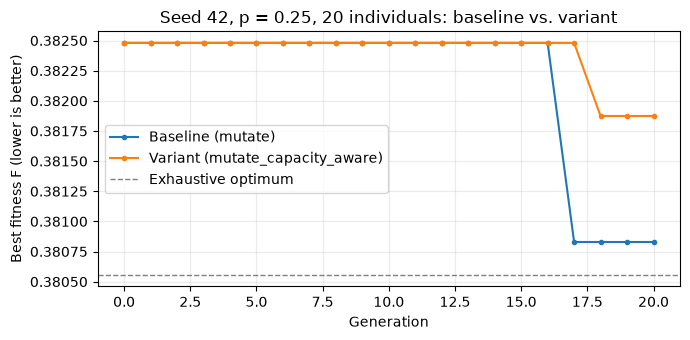

In [20]:
fig, ax = plt.subplots(figsize=(7, 3.5))
for label, result in dev_runs:
    ax.plot(range(len(result["history"])), result["history"], marker=".", label=label)
ax.axhline(opt["fitness"], color="grey", linestyle="--", linewidth=1, label="Exhaustive optimum")
ax.set(xlabel="Generation", ylabel="Best fitness F (lower is better)",
       title="Seed 42, p = 0.25, 20 individuals: baseline vs. variant")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation (seed 42).** Both runs start from the same population (best plan (6,6,5,7), $F=0.38248$) and stay on that plateau for 16 generations.

| | Baseline (`mutate`) | Variant (`mutate_capacity_aware`) |
|---|---|---|
| Final chromosome $k$ | (7,4,3,8) | (5,7,4,8) |
| Reuse fractions $x$ | (0.7, 0.4, 0.3, 0.8) | (0.5, 0.7, 0.4, 0.8) |
| Treated water $T_i$ (m³): A1 / Bib / Ced / A2 | 592.900 / 184.800 / 85.263 / 546.400 | 423.500 / 323.400 / 113.684 / 546.400 |
| Potable water $P_i$ (m³): A1 / Bib / Ced / A2 | 254.100 / 277.200 / 198.947 / 136.600 | 423.500 / 138.600 / 170.526 / 136.600 |
| Total $T$ (m³) | 1409.363 | 1406.984 |
| Total $P$ (m³) | **866.847** | 869.226 |
| Excess $E$ (m³) / slack (m³) | 0 / 0.637 | 0 / 3.016 |
| Feasible | Yes | Yes |
| Fitness $F$ | **0.380829** | 0.381874 |
| Gap to optimum (8,6,4,5) (m³ potable) | 0.621 | 3.000 |
| First improvement at generation | 17 | 18 |
| Infeasible children (all 380 generated) | 21.8% | **4.2%** |

*What the evidence supports.*
- **Mechanism, part (a) of the hypothesis: supported.** The share of infeasible children fell from 21.8% to 4.2%. The remaining 4.2% are crossover children that were already over capacity and that mutation either did not touch (each gene is selected with probability 0.25) or did not lower enough. Mutation itself no longer creates infeasible plans (checked in Section 16).
- **Outcome, part (b) of the hypothesis: not supported at seed 42.** The variant's final plan is feasible but uses **2.379 m³ more potable water** than the baseline ($\Delta F=+0.00104$). With this seed, the baseline is better.

*Why fewer wasted children did not give a better plan here.* Each run improved exactly once, late (generation 17 vs. 18), so the final plan depends on a single lucky event. After the first mutation the two runs consume random numbers differently and follow different paths, so this one improvement is not a controlled consequence of the operator. The variant also has a structural limitation that this run exposes: genes are visited in a fixed order, so a step down on a building can only make room for a step up on a building that comes *later* in the chromosome. Aulas 1, the first gene and the largest step (84.7 m³), can never be raised by the variant once the plan is near capacity. Getting there needs crossover. The baseline's plan (7,4,3,8) has Aulas 1 at 70%, and the variant's plan (5,7,4,8) has it at 50%, with the treated water shifted to Biblioteca and Cedetec. Both plans keep Aulas 2 at its 80% limit.

*Physical reading.* Both plans are feasible, use more than 99.7% of the 1,410 m³ teaching capacity and cut potable water from 2,276.21 m³ to about 867–869 m³ (about 62% less). The 2.379 m³ difference is 0.1% of total demand. Different building splits reach almost the same potable use, so the choice between these two plans would in practice depend on factors the model leaves out, such as piping, water quality and cost. (The variant's plan happens to equal the $p=0.50$ result of Section 9; it is a common near-boundary plan.)

## 19. B2 — Scope: is seed 42 representative?

The required comparison is the single seed-42 run above. One run cannot separate the effect of the operator from the luck of the random stream: once the operators differ, the two runs consume random numbers differently and follow different paths after the first mutation. To see how far the seed-42 result generalizes, we repeat the same paired comparison (same seed for both operators, otherwise `CONFIG`) on seeds 0–99. This is supplementary evidence. It does not replace the seed-42 comparison.

In [21]:
SEEDS = range(100)
rows = []
for s in SEEDS:
    cfg = {**CONFIG, "seed": s}
    b = run_ga_with(**cfg, mutation_operator=mutate)
    v = run_ga_with(**cfg, mutation_operator=mutate_capacity_aware)
    rows.append((s, b["metrics"]["potable"] - opt["potable"], v["metrics"]["potable"] - opt["potable"],
                 b["metrics"]["feasible"], v["metrics"]["feasible"],
                 b["infeasible_share"], v["infeasible_share"]))
seeds, gap_b, gap_v, feas_b, feas_v, inf_b, inf_v = map(np.array, zip(*rows))

diff = gap_v - gap_b  # negative: variant uses less potable water
wins, ties, losses = int(np.sum(diff < -1e-6)), int(np.sum(np.abs(diff) <= 1e-6)), int(np.sum(diff > 1e-6))
n = wins + losses
sign_p = min(1.0, 2 * sum(math.comb(n, j) for j in range(min(wins, losses) + 1)) / 2 ** n)

print(f"{'':<28}{'Baseline':>10}{'Variant':>10}")
print(f"{'Feasible final plans':<28}{feas_b.sum():>10d}{feas_v.sum():>10d}")
print(f"{'Optimum found (gap = 0)':<28}{np.sum(gap_b < 1e-6):>10d}{np.sum(gap_v < 1e-6):>10d}")
print(f"{'Mean gap (m3 potable)':<28}{gap_b.mean():>10.3f}{gap_v.mean():>10.3f}")
print(f"{'Median gap (m3 potable)':<28}{np.median(gap_b):>10.3f}{np.median(gap_v):>10.3f}")
print(f"{'Worst gap (m3 potable)':<28}{gap_b.max():>10.3f}{gap_v.max():>10.3f}")
print(f"{'Mean infeasible children':<28}{inf_b.mean():>10.1%}{inf_v.mean():>10.1%}")
print(f"\nPaired by seed: variant better in {wins}, equal in {ties}, worse in {losses} of {len(seeds)} seeds")
print(f"Two-sided sign test on the {n} untied seeds: p = {sign_p:.3f}")
print(f"Seeds with a larger loss for the variant than seed 42: {int(np.sum(diff > diff[seeds == 42][0]))}")

                              Baseline   Variant
Feasible final plans               100       100
Optimum found (gap = 0)             15        18
Mean gap (m3 potable)            2.285     1.603
Median gap (m3 potable)          2.000     0.621
Worst gap (m3 potable)          13.079     8.321
Mean infeasible children         16.3%      6.6%

Paired by seed: variant better in 49, equal in 17, worse in 34 of 100 seeds
Two-sided sign test on the 83 untied seeds: p = 0.124
Seeds with a larger loss for the variant than seed 42: 17


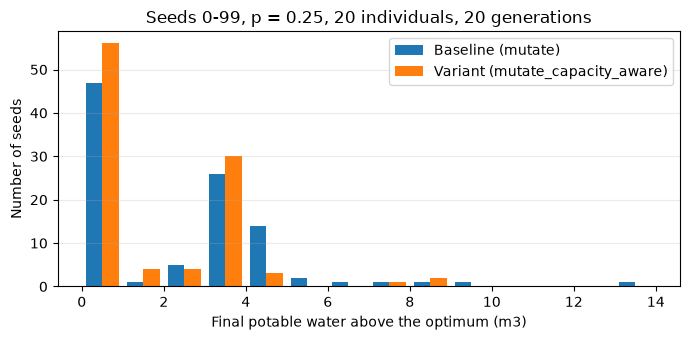

In [22]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bins = np.arange(0, max(gap_b.max(), gap_v.max()) + 1.5, 1.0)
ax.hist([gap_b, gap_v], bins=bins, label=["Baseline (mutate)", "Variant (mutate_capacity_aware)"])
ax.set(xlabel="Final potable water above the optimum (m3)", ylabel="Number of seeds",
       title="Seeds 0-99, p = 0.25, 20 individuals, 20 generations")
ax.grid(alpha=0.25, axis="y")
ax.legend()
fig.tight_layout()
plt.show()

**Interpretation (scope).** Over 100 paired seeds:

- Both operators always ended with a feasible plan, so the change does not affect feasibility of the final answer. Elitism plus the penalty already ensures that.
- The variant reduced infeasible children on average from 16.3% to 6.6%, consistent with seed 42. The mechanism is reproducible.
- The variant had a lower mean gap (1.603 vs. 2.285 m³), a lower median gap (0.621 vs. 2.000 m³), a smaller worst case (8.321 vs. 13.079 m³) and found the exact optimum more often (18 vs. 15 seeds).
- Paired by seed, the variant was better in 49 seeds, equal in 17 and worse in 34. A two-sided sign test gives $p=0.124$, so the advantage is a **trend, not a statistically established improvement**, at this budget and sample size.
- Seed 42 falls in the variant's unfavorable tail: only 17 of the 100 seeds had a larger loss for the variant. The seed-42 comparison is honest evidence, but on its own it would have suggested the opposite of the typical behavior.

**Scope of the conclusion.** These results hold for this teaching model only: four buildings, March 2025 demand, the 1,410 m³ teaching capacity, 20 individuals, 20 generations and $p=0.25$. We did not test other mutation probabilities, population sizes or budgets, and we did not tune the operator for performance. Its only revision, described in Section 16, fixed a guarantee before any reported run. The operator relies on the constraint being linear and cheap to compute, which holds here. The search space has only 5,103 plans, so exhaustive search finds the optimum directly. The GA comparison is about operator behavior, not about the best way to solve this instance. A natural next step, not tested here, is to visit the genes in a random order inside the mutation operator, so that any building can benefit from capacity freed by another.

## 20. B2 — Reproducibility check

We repeat both seed-42 runs and confirm that genes and fitness histories match, and that elitism keeps the best fitness from getting worse in both runs. We restarted the kernel and ran the whole notebook from top to bottom; Sections 1–13 reproduce their previous outputs.

In [23]:
for operator, result in [(mutate, dev_baseline), (mutate_capacity_aware, dev_variant)]:
    again = run_ga_with(**CONFIG, mutation_operator=operator)
    np.testing.assert_array_equal(result["genes"], again["genes"])
    np.testing.assert_array_equal(result["history"], again["history"])
    assert np.all(np.diff(result["history"]) <= 1e-12)
print("Both seed-42 runs reproduced; best fitness never worsens.")

Both seed-42 runs reproduced; best fitness never worsens.


## 21. Development evidence and conclusion

- **B1, functional cycle and justified modification:** limitation (Section 15), hypothesis and modified mutation operator with guarantee checks (Section 16), and the complete GA cycle running with either operator (Section 17).
- **B2, reproducibility and controlled comparison:** check that the baseline is preserved (Section 17), seed-42 comparison under identical conditions with chromosomes, per-building treated and potable water, fitness, excess and feasibility (Section 18), scope across seeds (Section 19) and reproduction checks (Section 20).

**Summary.**
- **Operator changed:** mutation. **Limitation addressed:** the baseline mutation ignores the capacity constraint, so near the boundary about half of its steps produce infeasible, uncompetitive children.
- **Hypothesis:** a capacity-aware mutation (downward steps always allowed, upward steps only if $T\le C$) will waste fewer children and lead to plans with less potable water.
- **Seed-42 result (same population, same parameters):** both final plans are feasible with $E=0$. The baseline (7,4,3,8) uses 866.847 m³ potable / 1409.363 m³ treated, $F=0.380829$; the variant (5,7,4,8) uses 869.226 m³ potable / 1406.984 m³ treated, $F=0.381874$. The variant is **worse by 2.379 m³** with this seed, even though it reduced infeasible children from 21.8% to 4.2%.
- **Scope:** across 100 seeds the variant shows a favorable but not significant trend (49 better / 17 equal / 34 worse; sign test $p=0.124$), and seed 42 is one of its less favorable seeds. The mechanism (fewer infeasible children) is supported; better final plans in general are not established.

Results describe this teaching model; they are not a validated hydraulic or sanitary recommendation.

# Deliverable 3

## 22. Final: identified code version and what we build on

This section completes the cumulative notebook. Sections 1–13 hold the Research work (formulation, hand calculation, exhaustive optimum) and Sections 14–21 the Development work (baseline GA, capacity-aware mutation variant, controlled comparison at seed 42). We reuse the Development variant `mutate_capacity_aware` as the identified code version for Final: it is the same code that produced `dev_variant` in Section 18, and no operator has changed since.

The three Final criteria are:

- **C1** Track one generation concretely, from parents to replacement.
- **C2** Compare p_m = 0.25 and p_m = 0.50 with the same code, same population, same seed.
- **C3** Interpret the water allocation by building, capacity and assumptions.

We confirm that the p=0.25 rerun matches Development before comparing.

## 23. C1 — One generation, traced step by step

We reproduce exactly the seed-42 run of `mutate_capacity_aware` at p=0.25 and log every decision inside a generation. The two generations we show are:

- **Generation 1**: the full cycle from the initial population, with all 19 children listed. This is the clearest way to see each operator working on the whole population.
- **Generation 18**: the only generation in this run where a child beats the elite and lowers the best fitness. We follow that child from its two tournaments to the new population, and we log each gene decision inside the mutation.

`trace_one_generation` below mirrors `next_generation_with` (Section 17) step by step. It draws random numbers in exactly the same order, so the population sequence matches `dev_variant` exactly. We verify this with an assertion.

In [24]:
def trace_one_generation(population, probability, rng, mutation_operator):
    """Run one generation step by step, recording every decision."""
    elite = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    replacement = [elite]
    log = []
    while len(replacement) < len(population):
        idx_a = tuple(int(i) for i in rng.choice(len(population), size=2, replace=False))
        winner_a = int(min(idx_a, key=lambda i: evaluate(population[i])["fitness"]))
        parent_a = population[winner_a].copy()
        idx_b = tuple(int(i) for i in rng.choice(len(population), size=2, replace=False))
        winner_b = int(min(idx_b, key=lambda i: evaluate(population[i])["fitness"]))
        parent_b = population[winner_b].copy()
        cut = int(rng.integers(1, len(LIMITS)))
        child_xo = np.concatenate((parent_a[:cut], parent_b[cut:]))
        child = mutation_operator(child_xo.copy(), probability, rng)
        log.append(dict(
            idx_a=idx_a, winner_a=winner_a, parent_a=parent_a.copy(),
            f_a=evaluate(parent_a)["fitness"],
            idx_b=idx_b, winner_b=winner_b, parent_b=parent_b.copy(),
            f_b=evaluate(parent_b)["fitness"],
            cut=cut, child_xo=child_xo, f_xo=evaluate(child_xo)["fitness"],
            child=child, f_child=evaluate(child)["fitness"],
            metrics_child=evaluate(child),
        ))
        replacement.append(child)
    return dict(
        population_in=[x.copy() for x in population],
        elite=elite, elite_fitness=evaluate(elite)["fitness"],
        log=log, population_out=replacement,
        best_in=min(evaluate(x)["fitness"] for x in population),
        best_out=min(evaluate(x)["fitness"] for x in replacement),
    )


def run_ga_traced(target_generation, population_size=20, generations=20,
                  mutation_probability=0.25, seed=42, mutation_operator=mutate):
    """Run the GA cycle and capture a full trace of one generation."""
    rng = np.random.default_rng(seed)
    population = [random_individual(rng) for _ in range(population_size)]
    history = [min(evaluate(x)["fitness"] for x in population)]
    trace = None
    for gen in range(1, generations + 1):
        if gen == target_generation:
            trace = trace_one_generation(population, mutation_probability, rng, mutation_operator)
            population = trace["population_out"]
        else:
            population = next_generation_with(population, mutation_probability, rng,
                                              mutation_operator, stats=dict(children=0, infeasible=0))
        history.append(min(evaluate(x)["fitness"] for x in population))
    best = min(population, key=lambda x: evaluate(x)["fitness"]).copy()
    return trace, dict(genes=best, metrics=evaluate(best), history=np.array(history))


def show_child(c, rank=None):
    """Format one child's decision path."""
    tag = f"child {rank}: " if rank else ""
    print(f"  {tag}A wins indices {c['idx_a']} (individual {c['winner_a']}), genes {tuple(int(v) for v in c['parent_a'])}, F = {c['f_a']:.6f}")
    print(f"  {tag}B wins indices {c['idx_b']} (individual {c['winner_b']}), genes {tuple(int(v) for v in c['parent_b'])}, F = {c['f_b']:.6f}")
    print(f"  {tag}cut = {c['cut']}, child before mutation = {tuple(int(v) for v in c['child_xo'])}, F = {c['f_xo']:.6f}")
    print(f"  {tag}child after mutation = {tuple(int(v) for v in c['child'])}, F = {c['f_child']:.6f}, feasible = {c['metrics_child']['feasible']}")

In [25]:
trace1, result1 = run_ga_traced(1, **CONFIG, mutation_operator=mutate_capacity_aware)
np.testing.assert_array_equal(result1["genes"], dev_variant["genes"])
np.testing.assert_array_equal(result1["history"], dev_variant["history"])
print("Trace reproduces the Development p=0.25 run exactly.")
print()

sorted_in = sorted(enumerate(trace1["population_in"]),
                   key=lambda x: evaluate(x[1])["fitness"])
print("Population entering generation 1 (sorted by F, lower is better):")
print(f"  rank  idx  genes               F          feasible")
for rank, (idx, genes) in enumerate(sorted_in, 1):
    m = evaluate(genes)
    print(f"  {rank:>4}  {idx:>3}  {str(tuple(int(v) for v in genes)):<19} {m['fitness']:.6f}   {m['feasible']}")
print()

print(f"Elite copied unchanged: {tuple(int(v) for v in trace1['elite'])}, F = {trace1['elite_fitness']:.6f}")
print()

print("All 19 children generated in generation 1:")
print(f"  {'#':>3}  {'parent A':<14}{'F_A':>9}  {'parent B':<14}{'F_B':>9}  {'cut':>3}  "
      f"{'child after XO':<16}{'child after mut':<16}{'F_child':>9}  {'feasible':>8}  {'beats elite':>11}")
for i, c in enumerate(trace1["log"], 1):
    beats = "yes" if c["f_child"] < trace1["elite_fitness"] - 1e-12 else "no"
    print(f"  {i:>3}  {str(tuple(int(v) for v in c['parent_a'])):<14}{c['f_a']:>9.6f}  "
          f"{str(tuple(int(v) for v in c['parent_b'])):<14}{c['f_b']:>9.6f}  {c['cut']:>3}  "
          f"{str(tuple(int(v) for v in c['child_xo'])):<16}{str(tuple(int(v) for v in c['child'])):<16}"
          f"{c['f_child']:>9.6f}  {str(c['metrics_child']['feasible']):>8}  {beats:>11}")
print()

print(f"Best fitness before generation 1: {trace1['best_in']:.6f}")
print(f"Best fitness after generation 1:  {trace1['best_out']:.6f}")
print()

print("Detail for the first child:")
show_child(trace1["log"][0], rank=1)

Trace reproduces the Development p=0.25 run exactly.

Population entering generation 1 (sorted by F, lower is better):
  rank  idx  genes               F          feasible
     1    3  (6, 6, 5, 7)        0.382480   True
     2    6  (7, 5, 2, 7)        0.403024   True
     3    9  (7, 7, 1, 5)        0.434929   True
     4    5  (4, 3, 1, 8)        0.537731   True
     5   12  (6, 7, 5, 1)        0.542219   True
     6   11  (0, 8, 3, 8)        0.560118   True
     7    1  (3, 7, 0, 6)        0.566253   True
     8   14  (4, 1, 5, 6)        0.588393   True
     9    4  (4, 1, 5, 4)        0.648405   True
    10   18  (4, 1, 4, 4)        0.660891   True
    11   19  (2, 2, 3, 6)        0.667490   True
    12   16  (3, 2, 6, 3)        0.682839   True
    13    2  (1, 0, 3, 8)        0.685283   True
    14    7  (4, 3, 3, 2)        0.692795   True
    15   10  (1, 6, 4, 3)        0.701045   True
    16    0  (0, 6, 4, 3)        0.738256   True
    17   13  (3, 4, 3, 0)        0.769721   

In [26]:
import copy

mutation_log = []


def mutate_capacity_aware_logged(child, probability, rng):
    """Call mutate_capacity_aware and record each gene decision it makes."""
    reference_rng = copy.deepcopy(rng)
    result = mutate_capacity_aware(child, probability, rng)
    # Replay the same random draws on a copy of the generator to record each decision.
    replay, steps = child.copy(), []
    for i, limit in enumerate(LIMITS):
        selected = reference_rng.random() < probability
        treated = float(np.sum(DEMAND * replay / 10))
        neighbors = [int(v) for v in (replay[i] - 1, replay[i] + 1) if 0 <= v <= limit]
        allowed = [v for v in neighbors
                   if v < replay[i] or treated + DEMAND[i] / 10 <= CAPACITY + 1e-8]
        before = int(replay[i])
        if selected and allowed:
            replay[i] = reference_rng.choice(allowed)
        steps.append(dict(building=BUILDINGS[i], selected=selected, before=before,
                          treated_before=treated, neighbors=neighbors, allowed=allowed,
                          after=int(replay[i])))
    np.testing.assert_array_equal(replay, result)
    mutation_log.append(steps)
    return result


trace18, result18 = run_ga_traced(18, **CONFIG, mutation_operator=mutate_capacity_aware_logged)
np.testing.assert_array_equal(result18["genes"], dev_variant["genes"])
np.testing.assert_array_equal(result18["history"], dev_variant["history"])
print("Trace reproduces the Development p=0.25 run exactly.")
print()

pop_in = trace18["population_in"]
fit = lambda x: evaluate(x)["fitness"]
k = next(i for i, c in enumerate(trace18["log"]) if c["f_child"] < trace18["best_in"] - 1e-12)
winning = trace18["log"][k]
n_children = CONFIG["population_size"] - 1
steps = mutation_log[17 * n_children + k]  # 19 mutation calls per generation

print(f"Generation 18, child {k + 1} of {n_children}")
print("1. Selection (binary tournaments)")
for tag, idx, w in [("A", winning["idx_a"], winning["winner_a"]),
                    ("B", winning["idx_b"], winning["winner_b"])]:
    contestants = ", ".join(f"#{i} {tuple(int(v) for v in pop_in[i])} F={fit(pop_in[i]):.6f}" for i in idx)
    print(f"   parent {tag}: {contestants} -> winner #{w}")
print("2. One-point crossover")
c = winning["cut"]
print(f"   cut = {c}: genes 1-{c} from A {tuple(int(v) for v in winning['parent_a'][:c])} + "
      f"genes {c + 1}-4 from B {tuple(int(v) for v in winning['parent_b'][c:])} = "
      f"{tuple(int(v) for v in winning['child_xo'])}")
mx = evaluate(winning["child_xo"])
print(f"   T = {mx['treated']:.3f} m3, P = {mx['potable']:.3f} m3, feasible = {mx['feasible']}, F = {mx['fitness']:.6f}")
print("3. Capacity-aware mutation (p = 0.25 per gene, genes visited in order)")
for s in steps:
    if not s["selected"]:
        print(f"   {s['building']:<10} k = {s['before']}: not selected, unchanged")
    else:
        print(f"   {s['building']:<10} k = {s['before']}: selected, T before = {s['treated_before']:.3f} m3, "
              f"neighbors {s['neighbors']}, allowed {s['allowed']} -> k = {s['after']}")
mc = winning["metrics_child"]
print(f"   child = {tuple(int(v) for v in winning['child'])}: T = {mc['treated']:.3f} m3, "
      f"P = {mc['potable']:.3f} m3, E = {mc['excess']:.3f} m3, F = {mc['fitness']:.6f}")
print("4. Replacement with one elite")
print(f"   elite copied unchanged: {tuple(int(v) for v in trace18['elite'])}, F = {trace18['elite_fitness']:.6f}")
out = trace18["population_out"]
ranked = sorted(range(len(out)), key=lambda i: fit(out[i]))
print("   best five of the new population:")
for r, i in enumerate(ranked[:5], 1):
    tag = "elite" if i == 0 else f"child {i}"
    m = evaluate(out[i])
    print(f"     {r}. {str(tuple(int(v) for v in out[i])):<14} F = {m['fitness']:.6f}  T = {m['treated']:.3f}  ({tag})")
print(f"   best F: {trace18['best_in']:.6f} -> {trace18['best_out']:.6f} "
      f"({trace18['best_in'] - trace18['best_out']:.6f} lower, "
      f"{evaluate(trace18['elite'])['potable'] - mc['potable']:.3f} m3 less potable water)")
infeasible = sum(not c['metrics_child']['feasible'] for c in trace18['log'])
print(f"   infeasible children in this generation: {infeasible} of {n_children}")

Trace reproduces the Development p=0.25 run exactly.

Generation 18, child 2 of 19
1. Selection (binary tournaments)
   parent A: #12 (5, 7, 5, 6) F=0.429400, #9 (5, 5, 5, 7) F=0.439988 -> winner #12
   parent B: #10 (5, 6, 5, 7) F=0.419691, #7 (6, 4, 5, 7) F=0.423074 -> winner #10
2. One-point crossover
   cut = 2: genes 1-2 from A (5, 7) + genes 3-4 from B (5, 7) = (5, 7, 5, 7)
   T = 1367.105 m3, P = 909.105 m3, feasible = True, F = 0.399394
3. Capacity-aware mutation (p = 0.25 per gene, genes visited in order)
   AULAS 1    k = 5: not selected, unchanged
   BIBLIOTECA k = 7: not selected, unchanged
   CEDETEC    k = 5: selected, T before = 1367.105 m3, neighbors [4, 6], allowed [4, 6] -> k = 4
   AULAS 2    k = 7: selected, T before = 1338.684 m3, neighbors [6, 8], allowed [6, 8] -> k = 8
   child = (5, 7, 4, 8): T = 1406.984 m3, P = 869.226 m3, E = 0.000 m3, F = 0.381874
4. Replacement with one elite
   elite copied unchanged: (6, 6, 5, 7), F = 0.382480
   best five of the new pop

### What the trace shows, step by step

Every example below is a candidate printed by the two trace cells above (seed 42, $p_m=0.25$, `mutate_capacity_aware`).

**Fitness: why lower is better.** For a feasible plan, $F=P/2276.21$ is the share of demand still covered with potable water, so a lower $F$ means less potable water. A plan over capacity gets $F=1+E/1410>1$, so it loses every tournament against any feasible plan. Example from generation 1: child 18 is (6,6,5,8) with $T=1473.905$ m³ and $E=63.905$ m³. It would need only 802.305 m³ of potable water, but its $F=1.045323$ ranks it below every feasible plan.

**Selection.** Each parent is the winner of a binary tournament: two distinct individuals are sampled and the one with lower $F$ wins. In generation 1, child 1, the tournament drew #8 (0,4,6,0) with $F=0.843896$ and #17 (0,4,5,1) with $F=0.826376$. #17 won although it ranks 18th of 20, because it only had to beat a weaker plan. Selection favors good plans but does not always pick the best ones. In generation 18, the parents of the improving child came from the tournaments #12 (5,7,5,6) $F=0.429400$ vs. #9 (5,5,5,7) $F=0.439988$, and #10 (5,6,5,7) $F=0.419691$ vs. #7 (6,4,5,7) $F=0.423074$.

**Crossover.** One cut is drawn between gene positions. The genes before the cut come from parent A and the rest from parent B, so each building keeps its position. In generation 18, A = (5,7,5,6), B = (5,6,5,7) and the cut is 2, so the child is (5,7 | 5,7) = (5,7,5,7), with $T=1367.105$ m³ and $F=0.399394$. That is better than both parents (0.429400 and 0.419691) but still worse than the elite (0.382480). Crossover can also break capacity. In generation 1, child 18 combines the feasible elite (6,6,5,7) with the feasible (4,3,1,8) at cut 3 and gets (6,6,5,8), which is 63.905 m³ over capacity. No gene was selected for mutation, so the child stayed infeasible. The same happened to child 17.

**Mutation.** `mutate_capacity_aware` visits the genes in order and selects each one with probability 0.25. A selected gene moves one level. A downward step is always allowed, and an upward step only if $T$ stays at or below 1410 m³. For the generation-18 child (5,7,5,7):

- Aulas 1 and Biblioteca were not selected, so they stay at 5 and 7.
- Cedetec (5) was selected with $T=1367.105$ m³. Both 4 and 6 were allowed, because $1367.105+28.421=1395.526\le1410$. The draw chose 4, so $T$ fell to 1338.684 m³.
- Aulas 2 (7) was selected with $T=1338.684$ m³. One level adds 68.3 m³: $1338.684+68.3=1406.984\le1410$, so 8 was allowed and chosen. Before Cedetec moved down, the same step would have given 1435.405 m³ and been blocked.

The result is (5,7,4,8) with $T=1406.984$ m³, $P=869.226$ m³ and $F=0.381874$. This is the coordinated move described in Section 15: one building goes down by a small step and a later building goes up by a larger one, for a net gain of 39.879 m³ of treated water without exceeding capacity.

**Replacement and elitism.** The new population starts with an unchanged copy of the incoming best, (6,6,5,7) with $F=0.382480$, and the 19 children fill the other places. In generation 18 the child (5,7,4,8) has $F=0.381874$, so it becomes the best individual. Best $F$ falls by 0.000606, which is 1.379 m³ less potable water. The old elite is still in the new population, and children 8 and 11 are also copies of it, so the best value could not have become worse even if no child had improved. That is what happened in generation 1: none of the 19 children beat $F=0.382480$, so the elite kept the best value and the best fitness did not change. From generation 18 on, elitism copies (5,7,4,8) into every generation, which is why the history stays at 0.381874 until generation 20 (Section 20 checks that it never increases).

### Why this is the same code we used in Development

The assertions at the top of both trace cells check that the traced runs reproduce `dev_variant` exactly: same final genes, same history. The logged mutation in generation 18 also checks, at every call, that its recorded decisions give the same child as `mutate_capacity_aware`. The trace is therefore a faithful read of the Development p=0.25 run, not a reimplementation.

## 24. C2 — Comparing p_m = 0.25 and p_m = 0.50 with the same code

Both runs use the same identified code (`mutate_capacity_aware`), the same population size (20), the same number of generations (20) and the same seed (42). The only difference is the per-gene mutation probability. We rerun the p=0.25 configuration and assert that it matches `dev_variant` from Section 18, so the comparison is genuinely between two configurations of one code version.

In [27]:
def first_improvement_gen(history):
    for i in range(1, len(history)):
        if history[i] < history[0] - 1e-12:
            return i
    return None


final_025 = run_ga_with(population_size=20, generations=20,
                        mutation_probability=0.25, seed=42,
                        mutation_operator=mutate_capacity_aware)
final_050 = run_ga_with(population_size=20, generations=20,
                        mutation_probability=0.50, seed=42,
                        mutation_operator=mutate_capacity_aware)

np.testing.assert_array_equal(final_025["genes"], dev_variant["genes"])
np.testing.assert_array_equal(final_025["history"], dev_variant["history"])
print("p=0.25 rerun matches the Development variant exactly (same genes, same history).")
print()

for label, result in [("p_m = 0.25", final_025), ("p_m = 0.50", final_050)]:
    m = result["metrics"]
    g = result["genes"]
    fi = first_improvement_gen(result["history"])
    print(label)
    print(f"  final genes = {tuple(int(v) for v in g)}, fractions = {tuple(round(float(v), 1) for v in g/10)}")
    print(f"  T = {m['treated']:.3f} m3, P = {m['potable']:.3f} m3, E = {m['excess']:.3f} m3")
    print(f"  feasible = {m['feasible']}, F = {m['fitness']:.6f}")
    print(f"  first improvement at generation {fi} of 20")
    print(f"  infeasible children across the whole run = {result['infeasible_share']:.1%}")
    print(f"  distinct plans in final population = {result['unique_final']}")
    print()

diff_F = final_050["metrics"]["fitness"] - final_025["metrics"]["fitness"]
diff_P = final_050["metrics"]["potable"] - final_025["metrics"]["potable"]
if abs(diff_F) < 1e-12:
    outcome = "Both configurations reached the same final fitness."
elif diff_F < 0:
    outcome = f"p=0.50 reached a lower F by {-diff_F:.8f} (uses {-diff_P:.3f} m3 less potable water)."
else:
    outcome = f"p=0.25 reached a lower F by {diff_F:.8f} (uses {diff_P:.3f} m3 less potable water)."
print(outcome)

p=0.25 rerun matches the Development variant exactly (same genes, same history).

p_m = 0.25
  final genes = (5, 7, 4, 8), fractions = (0.5, 0.7, 0.4, 0.8)
  T = 1406.984 m3, P = 869.226 m3, E = 0.000 m3
  feasible = True, F = 0.381874
  first improvement at generation 18 of 20
  infeasible children across the whole run = 4.2%
  distinct plans in final population = 20

p_m = 0.50
  final genes = (5, 7, 4, 8), fractions = (0.5, 0.7, 0.4, 0.8)
  T = 1406.984 m3, P = 869.226 m3, E = 0.000 m3
  feasible = True, F = 0.381874
  first improvement at generation 7 of 20
  infeasible children across the whole run = 4.5%
  distinct plans in final population = 18

Both configurations reached the same final fitness.


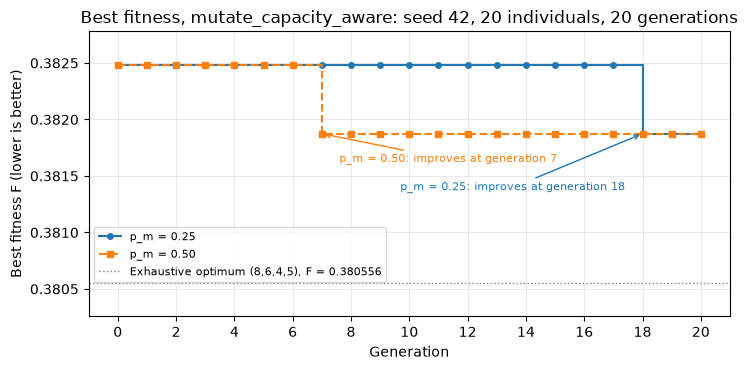

In [28]:
fig, ax = plt.subplots(figsize=(7.5, 3.8))
styles = {"p_m = 0.25": dict(color="tab:blue", linestyle="-", marker="o"),
          "p_m = 0.50": dict(color="tab:orange", linestyle="--", marker="s")}
for label, result in [("p_m = 0.25", final_025), ("p_m = 0.50", final_050)]:
    gens = range(len(result["history"]))
    ax.step(gens, result["history"], where="post", markersize=4, label=label, **styles[label])
    fi = first_improvement_gen(result["history"])
    left = fi > 10  # put the label on the side with free space
    ax.annotate(f"{label}: improves at generation {fi}", xy=(fi, result["history"][fi]),
                xytext=(fi - 0.6 if left else fi + 0.6, result["history"][fi] - (0.0005 if left else 0.00025)),
                ha="right" if left else "left", fontsize=8, color=styles[label]["color"],
                arrowprops=dict(arrowstyle="->", color=styles[label]["color"]))
ax.axhline(opt["fitness"], color="grey", linestyle=":", linewidth=1,
           label=f"Exhaustive optimum (8,6,4,5), F = {opt['fitness']:.6f}")
ax.set(xlabel="Generation", ylabel="Best fitness F (lower is better)", xticks=range(0, 21, 2),
       title="Best fitness, mutate_capacity_aware: seed 42, 20 individuals, 20 generations")
ax.set_ylim(opt["fitness"] - 0.0003, final_025["history"][0] + 0.0003)
ax.grid(alpha=0.25)
ax.legend(loc="lower left", bbox_to_anchor=(0.0, 0.1), fontsize=8)
fig.tight_layout()
plt.show()

### What changed and what stayed the same

Only the per-gene mutation probability differs. Everything else is fixed: initialization, selection (binary tournament), crossover (one-point, cut between genes 1 and 4), mutation operator (`mutate_capacity_aware`), replacement (generational with one elite), population size (20), generations (20), seed (42), data, gene domains and capacity.

### How to read the comparison

Both runs start from the same initial population, because the seed is the same and initialization happens before any mutation. The initial best is (6,6,5,7) with $F=0.382480$. After the first mutation draw, the two runs consume random numbers differently and follow different paths. With four genes, a child gets on average $4\times0.25=1$ selected gene at $p_m=0.25$ and $4\times0.50=2$ at $p_m=0.50$. More moves per child explore further from the parents, but they are also more likely to undo a good combination inherited from them.

### Result at seed 42

| Metric | $p_m=0.25$ | $p_m=0.50$ |
|---|---:|---:|
| Final genes | (5,7,4,8) | (5,7,4,8) |
| Fractions | (0.5, 0.7, 0.4, 0.8) | (0.5, 0.7, 0.4, 0.8) |
| Treated water $T$ (m³) | 1406.984 | 1406.984 |
| Potable water $P$ (m³) | 869.226 | 869.226 |
| Excess $E$ (m³) | 0.000 | 0.000 |
| Capacity margin (m³) | 3.016 | 3.016 |
| Feasible | Yes | Yes |
| Fitness $F$ | 0.381874 | 0.381874 |
| Gap to optimum (m³ potable) | 3.000 | 3.000 |
| Improvement at generation | 18 | 7 |
| Infeasible children (380 generated) | 4.2% | 4.5% |
| Distinct plans in final population | 20 | 18 |

**Reading the plot.** The curves are steps because the best fitness only changes when a child beats the elite. Each run improved exactly once, and in both runs that single improvement went straight from (6,6,5,7) to (5,7,4,8): at generation 7 with $p_m=0.50$ and at generation 18 with $p_m=0.25$. Neither curve ever rises, as elitism requires, and neither reaches the dotted line of the exhaustive optimum.

**Comparison.**
- **Final quality: tie.** Both configurations end with the same plan, the same $T$, $P$ and $F$, 3.000 m³ of potable water above the optimum (8,6,4,5).
- **Speed: $p_m=0.50$ was 11 generations faster at this seed.** Section 23 showed that, at $p_m=0.25$, (5,7,4,8) came from a two-gene move (Cedetec down, Aulas 2 up). A specific pair of genes is selected together in $0.25^2=6.25\%$ of children at $p_m=0.25$ and in $0.50^2=25\%$ at $p_m=0.50$, so two-gene moves are four times more frequent at the higher rate. This is a plausible reason for the earlier improvement; we did not trace the $p_m=0.50$ run, so we do not claim it is the cause.
- **Diversity.** The $p_m=0.50$ run ends with slightly fewer distinct plans (18 vs. 20), so the faster run did not end with a more diverse population.
- **Infeasible children.** The rates are similar (4.2% vs. 4.5%). `mutate_capacity_aware` cannot create infeasible plans, so these children come from crossover and were not repaired by mutation. Doubling $p_m$ did not reduce them.
- **Same pattern with the supplied baseline.** Section 9 ran the same two probabilities with the blind `mutate`. There $p_m=0.50$ also improved earlier (generation 5) and also ended at (5,7,4,8), while $p_m=0.25$ ended at (7,4,3,8) with 2.379 m³ less potable water. In both code versions, the higher rate improved earlier, but it did not finish with a better plan in either.

### What we can and cannot conclude

- At seed 42, with 20 individuals and 20 generations, the two probabilities give the same final plan; $p_m=0.50$ reaches it sooner.
- One seed cannot show which probability is better in general. A different seed could change the winner; Section 19 already showed that seed 42 is not representative for the operator comparison. We did not run a multi-seed study of $p_m$.
- Neither configuration found the optimum within the 400-evaluation budget, so the 3.000 m³ gap reflects the budget and the 10% gene steps as much as the mutation probability.

## 25. C3 — Physical interpretation by building

We break down the final plan of each configuration into the four buildings. For each building we show the demand $D_i$, the reuse fraction $x_i=k_i/10$, the treated water $T_i=x_iD_i$ and the potable water still needed $P_i=D_i-T_i$. In every row $T_i+P_i=D_i$, and the totals satisfy $T+P=Q=2276.21$ m³. The capacity margin $C-T=1410-T$ is the room left before capacity is exceeded.

The second cell puts the plan next to the exhaustive optimum (Section 12) and the treated water recorded for the same buildings in March 2025, so that we can separate what the model decides from what its assumptions impose.

In [29]:
for label, result in [("p_m = 0.25", final_025), ("p_m = 0.50", final_050)]:
    g = result["genes"]
    m = result["metrics"]
    print(f"{label} (seed 42)")
    print(f"  {'Building':<11}{'D (m3)':>9}{'x_i':>6}{'T_i (m3)':>11}{'P_i (m3)':>11}")
    for name, d, k in zip(BUILDINGS, DEMAND, g):
        print(f"  {name:<11}{d:>9.2f}{k/10:>6.1f}{d*k/10:>11.3f}{d-d*k/10:>11.3f}")
    print(f"  {'Total':<11}{DEMAND.sum():>9.2f}{'':>6}{m['treated']:>11.3f}{m['potable']:>11.3f}")
    print(f"  Capacity = {CAPACITY:.0f} m3, margin = {CAPACITY - m['treated']:.3f} m3, E = {m['excess']:.3f} m3")
    print(f"  Feasible = {m['feasible']}, F = {m['fitness']:.6f}")
    print()

p_m = 0.25 (seed 42)
  Building      D (m3)   x_i   T_i (m3)   P_i (m3)
  AULAS 1       847.00   0.5    423.500    423.500
  BIBLIOTECA    462.00   0.7    323.400    138.600
  CEDETEC       284.21   0.4    113.684    170.526
  AULAS 2       683.00   0.8    546.400    136.600
  Total        2276.21         1406.984    869.226
  Capacity = 1410 m3, margin = 3.016 m3, E = 0.000 m3
  Feasible = True, F = 0.381874

p_m = 0.50 (seed 42)
  Building      D (m3)   x_i   T_i (m3)   P_i (m3)
  AULAS 1       847.00   0.5    423.500    423.500
  BIBLIOTECA    462.00   0.7    323.400    138.600
  CEDETEC       284.21   0.4    113.684    170.526
  AULAS 2       683.00   0.8    546.400    136.600
  Total        2276.21         1406.984    869.226
  Capacity = 1410 m3, margin = 3.016 m3, E = 0.000 m3
  Feasible = True, F = 0.381874



In [30]:
# Treated water recorded per building in March 2025 (records kept in the notebook metadata,
# source consumo-agua.xlsx). Used only for context; the GA does not use these values.
RECORDED_TREATED = np.array([647.0, 317.0, 184.71, 289.0])

columns = [("GA plan, both p_m", final_025["genes"] * DEMAND / 10),
           ("Optimum (8,6,4,5)", optimum * DEMAND / 10),
           ("Recorded Mar 2025", RECORDED_TREATED)]
print("Treated water T_i in m3 (reuse fraction x_i in brackets)")
print(f"  {'Building':<11}{'limit':>6}" + "".join(f"{name:>22}" for name, _ in columns))
for i, name in enumerate(BUILDINGS):
    print(f"  {name:<11}{LIMITS[i] / 10:>6.1f}"
          + "".join(f"{t[i]:>14.3f} ({t[i] / DEMAND[i]:.2f})" for _, t in columns))
for row, value in [("Total T", lambda t: t.sum()),
                   ("Potable P", lambda t: DEMAND.sum() - t.sum()),
                   ("C - T", lambda t: CAPACITY - t.sum())]:
    print(f"  {row:<17}" + "".join(f"{value(t):>21.3f} " for _, t in columns))
print()

ga_potable = DEMAND - columns[0][1]
print("Potable water still needed in the GA plan, by building:")
for name, p in zip(BUILDINGS, ga_potable):
    print(f"  {name:<11}{p:>9.3f} m3  ({p / ga_potable.sum():.1%} of P)")
print(f"\nSmallest single step (one level of CEDETEC) = {DEMAND.min() / 10:.3f} m3 "
      f"> GA margin of {CAPACITY - columns[0][1].sum():.3f} m3")
print(f"Reduction of potable water with the GA plan: {1 - ga_potable.sum() / DEMAND.sum():.1%}")

Treated water T_i in m3 (reuse fraction x_i in brackets)
  Building    limit     GA plan, both p_m     Optimum (8,6,4,5)     Recorded Mar 2025
  AULAS 1       0.8       423.500 (0.50)       677.600 (0.80)       647.000 (0.76)
  BIBLIOTECA    0.8       323.400 (0.70)       277.200 (0.60)       317.000 (0.69)
  CEDETEC       0.6       113.684 (0.40)       113.684 (0.40)       184.710 (0.65)
  AULAS 2       0.8       546.400 (0.80)       341.500 (0.50)       289.000 (0.42)
  Total T                       1406.984              1409.984              1437.710 
  Potable P                      869.226               866.226               838.500 
  C - T                            3.016                 0.016               -27.710 

Potable water still needed in the GA plan, by building:
  AULAS 1      423.500 m3  (48.7% of P)
  BIBLIOTECA   138.600 m3  (15.9% of P)
  CEDETEC      170.526 m3  (19.6% of P)
  AULAS 2      136.600 m3  (15.7% of P)

Smallest single step (one level of CEDETEC) = 28.

### What the allocation means, building by building

Both configurations end with the same plan, (5,7,4,8). It sends 1,406.984 m³ of treated water to the four buildings and leaves 869.226 m³ of potable water, 61.8% less than the 2,276.21 m³ needed with no reuse.

- **Aulas 2** is at its 80% limit: 546.400 m³ treated and 136.600 m³ potable, the largest treated volume in the plan. Its remaining 20% of potable water is set by the teaching limit, not by capacity.
- **Aulas 1** is the largest building but gets only 50% (423.500 m³). It still needs 423.500 m³ of potable water, 48.7% of all the potable water the plan requires.
- **Biblioteca** is at 70%, one level below its limit (323.400 m³ treated, 138.600 m³ potable).
- **Cedetec** is at 40%, two levels below its 60% limit (113.684 m³ treated, 170.526 m³ potable).

**The split is not a ranking of buildings.** Fitness depends only on the total treated water: one m³ of treated water saves exactly one m³ of potable water, whichever building receives it. The model has no reason to prefer a building. The split comes from arithmetic: the GA combines steps of 84.7, 46.2, 28.421 and 68.3 m³ to get as close as possible to 1,410 m³ without passing it. The exhaustive optimum (8,6,4,5) shows this clearly. It puts Aulas 1 at 80% and Aulas 2 at 50%, almost the opposite emphasis, and needs only 3.000 m³ less potable water (0.13% of demand). Deciding which building should receive treated water first would require factors that the model leaves out: the distance and piping from the plant, the uses of water in each building and the water quality each use needs.

**Capacity is the active constraint.** The plan uses 1,406.984 of the 1,410 m³ (99.8%). The 3.016 m³ that are left cannot be used by any single step, because the smallest one (one level of Cedetec) is 28.421 m³. Only a coordinated change, one building down and another up, can use that margin; this is how the optimum reaches a margin of 0.016 m³. Without the capacity limit, every building would go to its reuse limit, (8,8,6,8), with 512.084 m³ of potable water; at this plan, the capacity costs 357.142 m³ of potable water compared with that case. Only Aulas 2 is at its own limit, so the plan is shaped mainly by the capacity, not by the per-building limits.

**Assumptions, and what the March 2025 records show.**

1. **Demand.** The March 2025 aggregate demands are treated as fixed. Another month would change the size of each step and, possibly, the plan.
2. **Capacity.** $C=1410$ m³ is the instructor's teaching calibration, not confirmed plant data. The records for these four buildings show 1,437.71 m³ of treated water used in March 2025, 27.71 m³ more than this capacity, so 1,410 m³ should not be read as a measured plant limit.
3. **Per-building limits.** The 80%, 80%, 60% and 80% limits are teaching assumptions, not pipe or water-quality constraints. The records show Cedetec at 65% treated water, above its 60% teaching limit.
4. **The recorded split is different from the GA plan.** In March 2025 the recorded fractions were 76% (Aulas 1), 69% (Biblioteca), 65% (Cedetec) and 42% (Aulas 2), with 838.5 m³ of potable water. That is 30.726 m³ less potable water than the GA plan, but it uses more treated water than the teaching capacity allows. The GA plan is the best plan within this model's constraints; it does not show that the current operation can be improved.

**Scope.** The model works with monthly aggregate volumes. It ignores daily timing, storage, water quality, pipe capacity and cost. Genes move in 10% steps, so the plan is coarse. Each configuration ran once with one seed and a population of 20, so the comparison is evidence about operator behavior at that scale, not proof that either $p_m$ is better. Results describe this teaching model; they are not a validated hydraulic or sanitary recommendation.

## 26. Final evidence and conclusion

**C1, one generation from parents to replacement (Section 23).** We trace the identified code version (`mutate_capacity_aware`, $p_m=0.25$, seed 42). Generation 1 shows the full cycle from the initial population: the elite copied unchanged, then 19 children with their tournaments, cut points, genes before and after mutation, fitness and feasibility. It also shows that two feasible parents can produce an infeasible child, and that no child beat the elite. Generation 18 follows the one child that improves the run: tournaments #12 vs. #9 and #10 vs. #7, crossover at cut 2 into (5,7,5,7), a gene-by-gene capacity-aware mutation (Cedetec 5→4 frees room for Aulas 2 7→8) and replacement, where (5,7,4,8) becomes the new best while the old elite is kept. Both traces reproduce `dev_variant` exactly.

**C2, $p_m=0.25$ vs. $p_m=0.50$ (Section 24).** Same code, 20 individuals, 20 generations and seed 42; only $p_m$ changes, and the $p_m=0.25$ rerun matches Development. Both runs end at (5,7,4,8) with $T=1406.984$ m³, $P=869.226$ m³ and $F=0.381874$, a tie on outcome, 3.000 m³ above the optimum. $p_m=0.50$ reached that plan at generation 7 and $p_m=0.25$ at generation 18. This is one seed, so we make no general claim about which probability is better.

**C3, physical interpretation (Section 25).** The final plan uses 99.8% of the teaching capacity and cuts potable water by 61.8%. Aulas 2 is at its 80% limit while Aulas 1, the largest building, stays at 50% and keeps about half of the remaining potable water. Because fitness depends only on total treated water, the split by building is a consequence of the step sizes and the capacity, not a priority between buildings; the optimum reaches almost the same potable water with a very different split. The capacity and per-building limits are teaching assumptions, and the March 2025 records exceed both. The results describe this teaching model and are not a validated hydraulic or sanitary recommendation.

**Preserved evidence.** Sections 1–13 (Research A1 and A2) and Sections 14–21 (Development B1 and B2) keep their code and results. The Final sections add the C1 trace, the C2 comparison and the C3 interpretation on top of that base. The full notebook reproduces from a fresh kernel: each trace assertion confirms that the sequence reproduces `dev_variant`, the $p_m=0.25$ rerun in C2 reproduces the same, and the reproducibility checks in Section 20 already confirm that both seed-42 runs rerun identically.

**Team.** Ángel Nicolás Landa Tapia (A01668133), Luis Fernando Salas López (A01770922), Claudio Ahuatzi Quintana (A01661936). Role rotation for this milestone, following the same pattern as Research and Development: driver records the C1 trace and the C2 comparison, reviewer checks the C2 interpretation and the C3 limitations, verifier confirms that the trace reproduces `dev_variant` and that the $p_m=0.25$ rerun in C2 matches Development.